# DS-A2 | Inference and Uncertainty — Geochemical Data Analysis

**Scope:** Reproducible statistical investigation of uncertainty in sedimentary phosphorite ΣREY concentrations using published bulk-rock and in situ apatite geochemical data.

**Study A:** Comparison of mean bulk-rock ΣREY concentrations between the Upper Phosphorite Layer (UPL) and Lower Phosphorite Layer (LPL), including simulation, confidence intervals, lithological sensitivity, and statistical power.

**Study B:** Comparison of pseudo-oolite and pellet apatite ΣREY concentrations, accounting for repeated analytical spots within parent rock samples through parent-level summaries and cluster-aware resampling.

**Counterexample:** Synthetic simulation demonstrating how ignoring parent-rock dependence can distort confidence-interval coverage and hypothesis-test calibration.

**Source:** Ali et al. (2026), *Journal of Asian Earth Sciences*. DOI: 10.1016/j.jseaes.2025.106927. The original supplementary Excel workbook is retained unchanged.

**Analysis status:** The questions and methods were developed retrospectively using published observations. The analyses are exploratory and were not prospectively preregistered. Statistical findings are interpreted conditionally on their stated assumptions.

## 1. Working targets (not yet results)
- **A:** UPL minus LPL mean whole-rock ΣREY, in ppm. Target limited to material represented by sampling at this section; representativeness requires assumptions.
- **B:** Equal-layer-weighted pseudo-oolite minus pellet mean in situ apatite ΣREY, first summarizing available spot measurements per parent sample and grain type. Parent rock samples, not spots, are candidate resampling units.
- **Proposed benchmark:** 100 ppm difference (sensitivity: 50 and 150 ppm). This is a planning benchmark, **not** a validated economic or geological cutoff.

**Do not infer causality from either contrast.** The published group descriptions were known when questions were selected.

### Research Hypotheses and Retrospective Analysis Status

**Study A — Bulk-Rock ΣREY**

Research question: Is the mean bulk-rock ΣREY concentration different between UPL and LPL?

Estimand:

\[
\Delta_A = \mu_{\mathrm{UPL}} - \mu_{\mathrm{LPL}}
\]

Null hypothesis: \(H_{0,A}: \Delta_A = 0\)

Alternative hypothesis: \(H_{1,A}: \Delta_A \neq 0\)

The comparison uses the available bulk-rock observations from both layers, including their original lithological composition.

**Study B — In Situ Apatite ΣREY**

Research question: Is mean apatite ΣREY concentration different between pseudo-oolites and pellets after accounting for parent-rock clustering and stratigraphic layers?

Estimand:

\[
\Delta_B = \frac{1}{3}\sum_{\ell \in \{\mathrm{LPL,MPL,UPL}\}} \left(\mu_{\mathrm{pseudo},\ell}-\mu_{\mathrm{pellet},\ell}\right)
\]

The grain-type means are defined using available parent-rock-level summaries, rather than treating every analytical spot as an independent rock sample.

Null hypothesis: \(H_{0,B}: \Delta_B = 0\)

Alternative hypothesis: \(H_{1,B}: \Delta_B \neq 0\)

**Minimum Meaningful Effect**

A difference of 100 ppm is used as a provisional practical-effect benchmark, with sensitivity considerations at 50 and 150 ppm. These values are illustrative planning choices and have not been independently established as geological or economic significance thresholds.

**Analysis Status and Transparency**

The research questions were developed retrospectively using previously published geochemical observations. The analysis methods, hypotheses, and practical-effect benchmark were not preregistered before the original data were collected, nor were all methodological choices frozen before the exploratory analyses were executed.

Accordingly, the findings are presented as retrospective, exploratory statistical inferences rather than prospectively confirmed hypotheses. The analysis retains sensitivity results, assumption limitations, and outcomes that challenge the original enrichment interpretation.

In [1]:
import sys
import numpy
import pandas

print("Python:", sys.version)
print("Interpreter:", sys.executable)
print("NumPy:", numpy.__version__)
print("pandas:", pandas.__version__)

Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Interpreter: e:\Asssessment Team\PhD\Data Science\.venv\Scripts\python.exe
NumPy: 2.5.4
pandas: 3.0.6


In [2]:
from pathlib import Path
import hashlib
import platform
import sys
import numpy as np
import pandas as pd

SEED = 20261012
rng = np.random.default_rng(SEED)
DATA = Path("Supplementary file.xlsx")
assert DATA.exists(), f"Copy original Excel file next to notebook: {DATA}"
print("Python:", sys.version.split()[0], "OS:", platform.platform())
print("NumPy:", np.__version__, "pandas:", pd.__version__)
print("Seed:", SEED)
print("Excel SHA256:", hashlib.sha256(DATA.read_bytes()).hexdigest())

Python: 3.13.9 OS: Windows-11-10.0.26300-SP0
NumPy: 2.5.4 pandas: 3.0.6
Seed: 20261012
Excel SHA256: 17343594cd7317c950a5ab7fd713c0928859a0a333ac20798d9da6ce645dd18b


## 2. Load original Excel tables
Excel row 2 contains Table S1 headers; Excel row 3 contains Table S2 headers. The row labels for layer and mineral phase are displayed once per group and must be carried forward carefully. Source file is never modified.

In [3]:
s1 = pd.read_excel(DATA, sheet_name="Supplementary file 1", header=1)
s2 = pd.read_excel(DATA, sheet_name="Supplementary file 2", header=2)
s1.columns = [str(c).strip() for c in s1.columns]
s2.columns = [str(c).strip() for c in s2.columns]
print("Raw dimensions:", s1.shape, s2.shape)
print("S1 headers of interest:", [c for c in s1 if "REY" in c or c in ("Lithology","S#No","P2O5")])
print("S2 headers of interest:", [c for c in s2 if "REY" in c or c in ("Points","Mineral phase","P2O5")])

Raw dimensions: (29, 83) (103, 75)
S1 headers of interest: ['Lithology', 'S#No', 'P2O5', '∑REY']
S2 headers of interest: ['Points', 'Mineral phase', 'P2O5', '∑REY']


## 3. Explicit identifiers and grouping labels
Record the *source row* to help trace potential data-cleaning issues back to Excel. Fill only known grouping-label columns, not measured values. Treat `Points` prefix as the parent rock identifier **within the stratigraphic layer**.

In [4]:
s1 = s1.rename(columns={s1.columns[0]: "layer", "S#No": "rock_sample", "∑REY": "sum_rey_ppm"})
s2 = s2.rename(columns={s2.columns[0]: "layer", "Points": "point_id", "Mineral phase": "mineral_phase", "∑REY": "sum_rey_ppm"})
s1["source_excel_row"] = np.arange(3, len(s1)+3)
s2["source_excel_row"] = np.arange(4, len(s2)+4)
for df in [s1,s2]:
    df["layer"] = df["layer"].ffill().astype("string").str.strip()
    df["sum_rey_ppm"] = pd.to_numeric(df["sum_rey_ppm"], errors="coerce")
s2["mineral_phase"] = s2.groupby("layer", sort=False)["mineral_phase"].ffill().astype("string").str.strip()
s2["grain_type"] = np.select([s2["mineral_phase"].str.contains("oolite",case=False,na=False), s2["mineral_phase"].str.contains("pellet",case=False,na=False)], ["pseudo-oolite","pellet"], default="UNRECOGNIZED")
s2["parent_number"] = s2["point_id"].astype("string").str.extract(r"^(\d+)-\d+$")[0]
s2["parent_rock_id"] = s2["layer"] + ":KG-" + s2["parent_number"].fillna("UNKNOWN")
assert not (s2["grain_type"]=="UNRECOGNIZED").any(), "Review mineral phase labels before proceeding"
assert s2["parent_number"].notna().all(), "Review point identifiers before proceeding"
print("Example spot/parent mapping:")
print(s2[["layer","point_id","parent_rock_id","mineral_phase","grain_type"]].head(12).to_string(index=False))

Example spot/parent mapping:
layer point_id parent_rock_id mineral_phase    grain_type
  LPL      2-1       LPL:KG-2   Oolite core pseudo-oolite
  LPL      2-2       LPL:KG-2   Oolite core pseudo-oolite
  LPL      2-3       LPL:KG-2   Oolite core pseudo-oolite
  LPL      5-1       LPL:KG-5   Oolite core pseudo-oolite
  LPL      5-2       LPL:KG-5   Oolite core pseudo-oolite
  LPL      5-3       LPL:KG-5   Oolite core pseudo-oolite
  LPL      6-1       LPL:KG-6   Oolite core pseudo-oolite
  LPL      6-2       LPL:KG-6   Oolite core pseudo-oolite
  LPL      4-1       LPL:KG-4    Oolite Rim pseudo-oolite
  LPL      4-2       LPL:KG-4    Oolite Rim pseudo-oolite
  LPL      7-1       LPL:KG-7    Oolite Rim pseudo-oolite
  LPL      7-2       LPL:KG-7    Oolite Rim pseudo-oolite


## 4. Data validation — no inferential results
Stop and reconcile any assertion failure with the actual Excel rows. Counts check dataset structure only; they do not validate random sampling, grain independence, or analytical uncertainty.

In [5]:
assert len(s1)==29 and len(s2)==103, "Unexpected number of source records"
assert s1["layer"].value_counts().to_dict()=={"MPL":11,"LPL":10,"UPL":8}, "Review S1 layer labels"
assert s2["layer"].value_counts().to_dict()=={"UPL":49,"MPL":33,"LPL":21}, "Review S2 layer labels"
assert s1["sum_rey_ppm"].notna().sum()==29
assert s2["sum_rey_ppm"].notna().sum()==103
print("S1 counts by layer:",s1.groupby("layer").size().to_dict())
print("S2 spots by layer/grain type:")
print(s2.groupby(["layer","grain_type"]).size().to_string())
print("S2 distinct parents by layer/grain type:")
print(s2.groupby(["layer","grain_type"])["parent_rock_id"].nunique().to_string())
print("S1 missing P2O5:",s1["P2O5"].isna().sum())
print("S2 missing initial 87Sr/86Sr:",s2["87Sr/86Sr Ini"].isna().sum())

S1 counts by layer: {'LPL': 10, 'MPL': 11, 'UPL': 8}
S2 spots by layer/grain type:
layer  grain_type   
LPL    pellet            7
       pseudo-oolite    14
MPL    pellet           16
       pseudo-oolite    17
UPL    pellet           18
       pseudo-oolite    31
S2 distinct parents by layer/grain type:
layer  grain_type   
LPL    pellet           4
       pseudo-oolite    6
MPL    pellet           7
       pseudo-oolite    9
UPL    pellet           5
       pseudo-oolite    8
S1 missing P2O5: 15
S2 missing initial 87Sr/86Sr: 76


## 5. Independent-verification checklist
- [ ] Open the original workbook and manually verify 3 randomly selected rows in each table against the loaded data.
- [ ] Confirm that the group labels were propagated correctly, particularly at group boundaries.
- [ ] Confirm with laboratory notebooks that point prefixes uniquely identify parent samples **within each layer**, and whether point suffixes reset under different mineral phases.
- [ ] Verify cross-table parent IDs before attempting any joins.
- [ ] Record the date at which estimands, benchmark, and methods were frozen.
- [ ] Record the notebook environment and package versions in requirements or lockfile.
- [ ] Retain any failed runs and all negative findings in the versioned repository.

**Next notebook section (to be built after checks):** simulation assumptions and sampling distribution. No interval, p-value, or power estimates are claimed here.

### Independent Verification — Final Status

The following verification activities were undertaken during the DS-A2 analysis:

**Completed checks**

- The original supplementary Excel workbook was inspected, including six selected source records across Tables S1 and S2.
- Stratigraphic group boundaries in the source tables were examined.
- The notebook's source-data structure and parent-rock identification procedures were reviewed.
- The manually calculated Study A Welch confidence interval was independently compared with SciPy's implementation, with numerical agreement verified.
- The power simulation and synthetic counterexample results were exported to CSV and checked through read-back comparisons.
- Python and scientific package versions were recorded in `requirements-lock.txt`.
- The notebook was successfully executed from a restarted kernel in VS Code.

**Limitations and outstanding verification**

- The six examined source records were selected to cover stratigraphic layers, rather than randomly sampled.
- Direct programmatic comparison of those six records against the processed dataframes has not yet been separately documented.
- Independent confirmation of analytical point identifiers against original laboratory notebooks remains outstanding.
- Cross-table parent-ID joins were not required for the primary statistical analyses.
- The research questions and analysis decisions were developed retrospectively and were not prospectively preregistered.
- Historical failed runs have not been comprehensively archived, although negative analytical findings and assumption limitations are retained.
- Independent reproduction on another computer has not yet been demonstrated.

These distinctions are retained to ensure that the verification record does not overstate the evidence available.

## 2. Sampling Distribution Simulation — Study A

**Objective:** Investigate how the estimated difference in mean bulk-rock ΣREY concentrations between the Upper and Lower phosphorite layers varies under repeated hypothetical sampling.

The simulation uses a normal sampling model with unequal group variances, calibrated to the observed data. Each simulated experiment contains 8 UPL and 10 LPL observations. The simulation will be repeated 10,000 times with a fixed random seed.

**Important assumptions:** Observations are simulated independently within each layer. Normality is assumed for this initial model. The simulated samples are hypothetical and do not represent additional geological measurements.

**Statistic:** Mean ΣREY (UPL) − Mean ΣREY (LPL), expressed in ppm.

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Fixed seed for reproducibility
rng = np.random.default_rng(20261012)

# Extract observations from the validated dataset
lpl = s1.loc[s1["layer"] == "LPL", "sum_rey_ppm"].dropna().to_numpy()
upl = s1.loc[s1["layer"] == "UPL", "sum_rey_ppm"].dropna().to_numpy()

# Observed descriptive statistics
n_lpl, n_upl = len(lpl), len(upl)

mean_lpl, mean_upl = np.mean(lpl), np.mean(upl)
sd_lpl, sd_upl = np.std(lpl, ddof=1), np.std(upl, ddof=1)

observed_difference = mean_upl - mean_lpl

# Simulate repeated samples under an explicit normal model
n_simulations = 10000

simulated_lpl = rng.normal(
    loc=mean_lpl, scale=sd_lpl, size=(n_simulations, n_lpl)
)

simulated_upl = rng.normal(
    loc=mean_upl, scale=sd_upl, size=(n_simulations, n_upl)
)

simulated_differences = (
    simulated_upl.mean(axis=1) - simulated_lpl.mean(axis=1)
)

print("LPL sample size:", n_lpl)
print("UPL sample size:", n_upl)
print(f"Observed mean difference: {observed_difference:.2f} ppm")
print(f"Mean simulated difference: {simulated_differences.mean():.2f} ppm")
print(f"Simulation SD: {simulated_differences.std(ddof=1):.2f} ppm")


LPL sample size: 10
UPL sample size: 8
Observed mean difference: 210.30 ppm
Mean simulated difference: 210.85 ppm
Simulation SD: 75.57 ppm


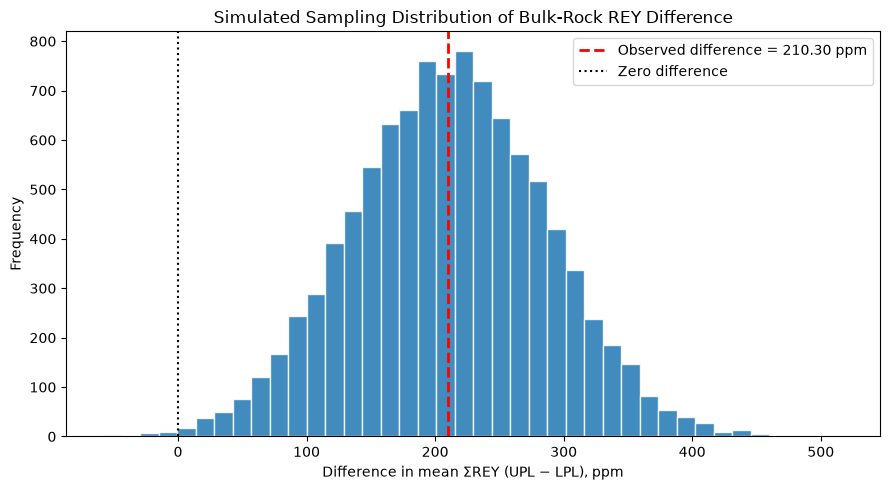

In [7]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    simulated_differences,
    bins=40,
    edgecolor="white",
    alpha=0.85
)

ax.axvline(
    observed_difference,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Observed difference = {observed_difference:.2f} ppm"
)

ax.axvline(
    0,
    color="black",
    linestyle=":",
    linewidth=1.5,
    label="Zero difference"
)

ax.set_xlabel("Difference in mean ΣREY (UPL − LPL), ppm")
ax.set_ylabel("Frequency")
ax.set_title("Simulated Sampling Distribution of Bulk-Rock REY Difference")
ax.legend()

plt.tight_layout()
plt.show()


In [8]:

# Verify simulated sampling variability

theoretical_se = np.sqrt(
    (sd_upl**2 / n_upl) +
    (sd_lpl**2 / n_lpl)
)

simulation_se = simulated_differences.std(ddof=1)

print(f"Theoretical standard error: {theoretical_se:.2f} ppm")
print(f"Simulated standard deviation: {simulation_se:.2f} ppm")
print(f"Absolute difference: {abs(theoretical_se - simulation_se):.2f} ppm")


Theoretical standard error: 75.99 ppm
Simulated standard deviation: 75.57 ppm
Absolute difference: 0.42 ppm


### Study A — Sampling Distribution Verification

The observed mean bulk-rock ΣREY difference between the Upper and Lower phosphorite layers was 210.30 ppm.

A Monte Carlo simulation of 10,000 hypothetical repeated sampling experiments, using independent normal sampling models with unequal group variances and a fixed random seed, produced a mean difference of 210.85 ppm and a sampling-distribution standard deviation of 75.57 ppm.

The theoretical standard error, calculated as the square root of the sum of the two sample-variance-to-sample-size ratios, was 75.99 ppm. The absolute discrepancy between the simulated and theoretical values was 0.42 ppm (approximately 0.55%).

This close agreement supports the computational consistency of the simulation under the specified normal, independent-sampling model. It does not independently validate the normality, independence, or geological representativeness assumptions.

The simulation illustrates sampling variability rather than providing a formal confidence interval or hypothesis test. Its interpretation is conditional on the model parameters estimated from the original geochemical observations.

In [9]:

from scipy import stats
import numpy as np

# Welch confidence interval for UPL minus LPL

alpha = 0.05

# Standard error
welch_se = np.sqrt(
    sd_upl**2 / n_upl +
    sd_lpl**2 / n_lpl
)

# Welch-Satterthwaite degrees of freedom
a = sd_upl**2 / n_upl
b = sd_lpl**2 / n_lpl

welch_df = (a + b)**2 / (
    (a**2 / (n_upl - 1)) +
    (b**2 / (n_lpl - 1))
)

# Critical t value
t_critical = stats.t.ppf(1 - alpha / 2, df=welch_df)

# 95% confidence interval
ci_lower = observed_difference - t_critical * welch_se
ci_upper = observed_difference + t_critical * welch_se

print(f"Observed mean difference: {observed_difference:.2f} ppm")
print(f"Welch standard error: {welch_se:.2f} ppm")
print(f"Degrees of freedom: {welch_df:.2f}")
print(f"95% confidence interval: [{ci_lower:.2f}, {ci_upper:.2f}] ppm")


Observed mean difference: 210.30 ppm
Welch standard error: 75.99 ppm
Degrees of freedom: 15.11
95% confidence interval: [48.44, 372.16] ppm


In [10]:

from scipy import stats

# Independent check using SciPy
welch_result = stats.ttest_ind(
    upl,
    lpl,
    equal_var=False
)

scipy_ci = welch_result.confidence_interval(
    confidence_level=0.95
)

print(f"Manual CI: [{ci_lower:.2f}, {ci_upper:.2f}] ppm")
print(f"SciPy CI:  [{scipy_ci.low:.2f}, {scipy_ci.high:.2f}] ppm")

# Verify agreement without relying on rounded values
assert np.allclose(
    [ci_lower, ci_upper],
    [scipy_ci.low, scipy_ci.high],
    rtol=1e-10
)

print("Verification passed: manual and SciPy intervals agree.")


Manual CI: [48.44, 372.16] ppm
SciPy CI:  [48.44, 372.16] ppm
Verification passed: manual and SciPy intervals agree.


### Study A — Welch Confidence Interval and Independent Verification

The estimated difference in mean bulk-rock ΣREY concentration between UPL and LPL was 210.30 ppm, with a Welch standard error of 75.99 ppm and approximately 15.11 degrees of freedom.

The resulting 95% Welch confidence interval was **48.44–372.16 ppm**. The interval excludes zero, providing evidence of a positive difference between the two layer means under the assumptions of the statistical model.

However, the interval overlaps the provisional minimum meaningful effect of 100 ppm. Consequently, although the data support a positive difference, they do not establish that the underlying difference exceeds the proposed meaningful-effect benchmark.

**Independent verification:** The manually calculated Welch confidence interval was compared with SciPy's `ttest_ind(..., equal_var=False).confidence_interval()` implementation. Both produced identical interval limits, with agreement verified using `np.allclose()` at full numerical precision.

**Limitations:** The interval assumes independent observations and relies on a parametric approximation with small sample sizes. Lithological heterogeneity, nonrandom sampling, and possible stratigraphic dependence may influence the reliability and geological interpretation of this result.

## 3. Nonparametric Bootstrap Confidence Interval — Study A

**Objective:** Estimate uncertainty in the difference between mean bulk-rock ΣREY concentrations in the Upper and Lower phosphorite layers using nonparametric bootstrap resampling.

The analysis resamples individual rock specimens independently within each stratigraphic layer, preserving the original sample sizes (UPL = 8; LPL = 10).

Each bootstrap sample is drawn with replacement, and the difference between the resampled means is calculated. The procedure is repeated 10,000 times with a fixed random seed.

A 95% percentile bootstrap confidence interval is constructed using the 2.5th and 97.5th percentiles of the bootstrap distribution.

**Assumptions and limitations:** The method assumes that the observed rock specimens adequately represent their respective target sampling distributions and that individual specimens can be treated as independent observations within layers. It does not automatically correct lithological heterogeneity, stratigraphic dependence, or preferential sample selection.

In [11]:

import numpy as np

# Fixed seed for reproducibility
bootstrap_rng = np.random.default_rng(20261013)

# Number of bootstrap repetitions
n_bootstrap = 10000

# Store bootstrap mean differences
bootstrap_differences = np.empty(n_bootstrap)

for i in range(n_bootstrap):

    # Resample rock specimens within each layer
    boot_lpl = bootstrap_rng.choice(
        lpl, size=n_lpl, replace=True
    )

    boot_upl = bootstrap_rng.choice(
        upl, size=n_upl, replace=True
    )

    # Calculate UPL minus LPL mean difference
    bootstrap_differences[i] = (
        np.mean(boot_upl) - np.mean(boot_lpl)
    )

# Calculate the percentile bootstrap confidence interval
bootstrap_ci = np.percentile(
    bootstrap_differences, [2.5, 97.5]
)

# Summarize the results
print(f"Observed mean difference: {observed_difference:.2f} ppm")
print(f"Bootstrap mean difference: {bootstrap_differences.mean():.2f} ppm")
print(f"Bootstrap standard error: {bootstrap_differences.std(ddof=1):.2f} ppm")

print(
    f"95% bootstrap CI: "
    f"[{bootstrap_ci[0]:.2f}, {bootstrap_ci[1]:.2f}] ppm"
)

print(
    f"95% Welch CI: "
    f"[{ci_lower:.2f}, {ci_upper:.2f}] ppm"
)


Observed mean difference: 210.30 ppm
Bootstrap mean difference: 210.59 ppm
Bootstrap standard error: 72.56 ppm
95% bootstrap CI: [68.41, 349.39] ppm
95% Welch CI: [48.44, 372.16] ppm


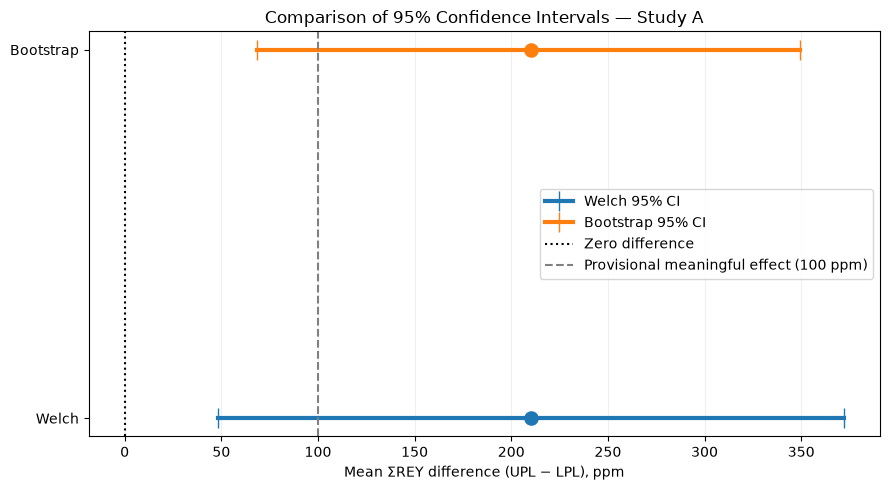

In [12]:

import matplotlib.pyplot as plt

# Confidence interval estimates from previous cells
methods = ["Welch", "Bootstrap"]

lower_bounds = np.array([
    ci_lower,
    bootstrap_ci[0]
])

upper_bounds = np.array([
    ci_upper,
    bootstrap_ci[1]
])

estimate = observed_difference

fig, ax = plt.subplots(figsize=(9, 5))

for i, method in enumerate(methods):
    ax.plot(
        [lower_bounds[i], upper_bounds[i]],
        [i, i],
        linewidth=3,
        marker="|",
        markersize=14,
        label=f"{method} 95% CI"
    )

    ax.scatter(
        estimate,
        i,
        s=90,
        zorder=3
    )

# Reference lines
ax.axvline(
    0,
    color="black",
    linestyle=":",
    label="Zero difference"
)

ax.axvline(
    100,
    color="gray",
    linestyle="--",
    label="Provisional meaningful effect (100 ppm)"
)

ax.set_yticks(range(len(methods)))
ax.set_yticklabels(methods)

ax.set_xlabel("Mean ΣREY difference (UPL − LPL), ppm")
ax.set_title("Comparison of 95% Confidence Intervals — Study A")

ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()

# Save a reproducible figure
plt.savefig("figures/Study_A_Confidence_Intervals.png", dpi=300, bbox_inches="tight")

plt.show()


## 4. Lithological Sensitivity Analysis — Study A

**Objective:** Evaluate whether the observed difference in mean bulk-rock ΣREY concentrations between UPL and LPL is sensitive to the lithological composition of the sampled rocks.

The original analysis includes all available rock types. However, LPL contains phosphorite, dolomitic phosphorite, cherty phosphorite, and chert, whereas UPL consists of samples classified as phosphorite.

We will first summarize ΣREY concentrations by lithology and stratigraphic layer. Then we will compare the original UPL–LPL mean difference with a restricted comparison using only phosphorite samples.

**Important limitation:** Restricting the analysis changes the population represented by the data and reduces the LPL sample size. The results cannot establish whether stratigraphy independently causes REY enrichment.

In [13]:

# Step 11A — Inspect lithological information in S1

print("Available S1 columns:")
print(s1.columns.tolist())

print("\nFirst five records:")
display(s1.head())

print("\nPossible lithology columns:")
print([
    col for col in s1.columns
    if "lith" in str(col).lower()
    or "rock" in str(col).lower()
    or "type" in str(col).lower()
])


Available S1 columns:
['layer', 'Lithology', 'rock_sample', 'Al2O3', 'BaO', 'CaO', 'F', 'TFe2O3', 'K2O', 'MgO', 'MnO', 'Na2O', 'NiO', 'P2O5', 'SiO2', 'SnO2', 'SO3', 'SrO', 'TiO2', 'LOI 1000', 'Ag', 'Al %', 'As', 'Be', 'Bi', 'Ca %', 'Cd', 'Co', 'Cr', 'Cs', 'Cu', 'Fe %', 'Ga', 'Ge', 'K %', 'Li', 'Mg %', 'Mn', 'Mo', 'Na %', 'Ni', 'Pb', 'Rb', 'S %', 'Sb', 'Sc', 'Sr', 'Th', 'Ti %', 'Tl', 'W', 'Zn', 'Ba', 'U', 'V', 'Zr', 'Nb', 'Hf', 'La', 'Ce', 'Pr', 'Nd', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Y', 'Ho', 'Er', 'Tm', 'Yb', 'Lu', 'sum_rey_ppm', 'Ce/Ce*', 'Pr/Pr*', 'Y/Y*', 'Eu/Eu*', 'Y/Ho', 'La/Yb', 'La/Sm', 'Sr/Ca', 'Rb/Sr', 'source_excel_row']

First five records:


,layer,Lithology,rock_sample,Al2O3,BaO,CaO,F,TFe2O3,K2O,MgO,...,Ce/Ce*,Pr/Pr*,Y/Y*,Eu/Eu*,Y/Ho,La/Yb,La/Sm,Sr/Ca,Rb/Sr,source_excel_row
0,LPL,Phosphorite,KG-1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.461981,1.187033,2.049242,0.942452,54.225352,0.790441,0.635754,0.002425,0.002405,3
1,LPL,Cherty Phosphorite,KG-2,0.19,0.01,32.00,2.2,0.27,0.08,0.06,...,0.472234,1.157552,1.965077,0.938297,50.174216,0.520933,0.640775,0.002854,0.004480,4
2,LPL,Dolomatic Phosphorite,KG-3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.508604,1.151692,1.910230,0.962789,49.021739,0.526751,0.700861,0.001159,0.032093,5
3,LPL,Chert,KG-4,0.83,0.03,4.71,0.3,1.04,0.21,0.09,...,0.527879,1.167751,1.997307,0.938046,50.909091,0.663721,0.942928,0.002738,0.072016,6
4,LPL,Chert,KG-5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.512466,1.154285,1.988974,1.008484,49.696970,0.576999,0.959183,0.003363,0.069544,7



Possible lithology columns:
['Lithology', 'rock_sample']


In [14]:

# Step 11B — Descriptive REY statistics by lithology and layer

# Inspect the original lithological labels
print("Original lithological categories:")
print(s1["Lithology"].value_counts(dropna=False))

# Create a working copy without modifying the original data
s1_lith = s1.copy()

# Standardize capitalization and surrounding spaces
s1_lith["lithology_clean"] = (
    s1_lith["Lithology"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

# Summarize REY concentrations
lithology_summary = (
    s1_lith
    .groupby(["layer", "lithology_clean"], dropna=False)
    ["sum_rey_ppm"]
    .agg(
        n="count",
        mean_ppm="mean",
        sd_ppm="std",
        min_ppm="min",
        max_ppm="max"
    )
    .reset_index()
)

print("\nREY concentrations by layer and lithology:")
display(lithology_summary.round(2))


Original lithological categories:
Lithology
Phosphorite              20
Dolomatic Phosphorite     6
Chert                     2
Cherty Phosphorite        1
Name: count, dtype: int64

REY concentrations by layer and lithology:


,layer,lithology_clean,n,mean_ppm,sd_ppm,min_ppm,max_ppm
0,LPL,chert,2,52.22,12.01,43.72,60.71
1,LPL,cherty phosphorite,1,325.11,NaN,325.11,325.11
2,LPL,dolomatic phosphorite,3,121.67,11.57,109.04,131.74
3,LPL,phosphorite,4,455.36,133.98,281.12,564.09
4,MPL,dolomatic phosphorite,3,194.50,146.62,96.23,363.03
5,MPL,phosphorite,8,466.59,96.71,318.47,565.95
6,UPL,phosphorite,8,471.90,121.03,334.17,643.59


In [15]:

# Step 11C — Phosphorite-only sensitivity comparison

# Select only samples classified as phosphorite
phosphorite_only = s1_lith[
    s1_lith["lithology_clean"] == "phosphorite"
].copy()

# Extract LPL and UPL phosphorite concentrations
lpl_phos = phosphorite_only.loc[
    phosphorite_only["layer"] == "LPL",
    "sum_rey_ppm"
].dropna().to_numpy()

upl_phos = phosphorite_only.loc[
    phosphorite_only["layer"] == "UPL",
    "sum_rey_ppm"
].dropna().to_numpy()

# Calculate the restricted difference
restricted_difference = (
    np.mean(upl_phos) - np.mean(lpl_phos)
)

# Compare with the original difference
change_in_difference = (
    restricted_difference - observed_difference
)

print("Original comparison:")
print(f"UPL - LPL difference: {observed_difference:.2f} ppm")

print("\nPhosphorite-only comparison:")
print(f"LPL sample size: {len(lpl_phos)}")
print(f"UPL sample size: {len(upl_phos)}")
print(f"LPL mean: {np.mean(lpl_phos):.2f} ppm")
print(f"UPL mean: {np.mean(upl_phos):.2f} ppm")
print(f"Restricted difference: {restricted_difference:.2f} ppm")

print("\nSensitivity to lithological restriction:")
print(f"Change in estimated difference: {change_in_difference:.2f} ppm")


Original comparison:
UPL - LPL difference: 210.30 ppm

Phosphorite-only comparison:
LPL sample size: 4
UPL sample size: 8
LPL mean: 455.36 ppm
UPL mean: 471.90 ppm
Restricted difference: 16.54 ppm

Sensitivity to lithological restriction:
Change in estimated difference: -193.76 ppm


In [16]:

# Step 11D — Welch CI for phosphorite-only comparison

from scipy import stats
import numpy as np

restricted_test = stats.ttest_ind(
    upl_phos,
    lpl_phos,
    equal_var=False
)

restricted_ci = restricted_test.confidence_interval(
    confidence_level=0.95
)

print("Phosphorite-only sensitivity analysis")
print(f"LPL n = {len(lpl_phos)}")
print(f"UPL n = {len(upl_phos)}")
print(f"Estimated difference: {restricted_difference:.2f} ppm")
print(
    f"95% Welch CI: "
    f"[{restricted_ci.low:.2f}, {restricted_ci.high:.2f}] ppm"
)


Phosphorite-only sensitivity analysis
LPL n = 4
UPL n = 8
Estimated difference: 16.54 ppm
95% Welch CI: [-181.84, 214.92] ppm


### Study A — Interpretation of Lithological Sensitivity

The original bulk-rock comparison produced an estimated mean ΣREY difference of 210.30 ppm between the Upper and Lower phosphorite layers, with a 95% Welch confidence interval of 48.44–372.16 ppm.

When the comparison was restricted to samples classified as phosphorite, the estimated difference decreased to 16.54 ppm. The corresponding 95% Welch confidence interval was −181.84 to 214.92 ppm.

The reduction of 193.76 ppm (approximately 92.1%) indicates that the estimated stratigraphic difference is highly sensitive to the lithological composition of the compared sample groups.

The restricted interval includes zero, meaning the available phosphorite-only observations do not provide sufficient evidence to establish a nonzero mean difference under the Welch model. However, this result does not demonstrate equivalence between the layers.

Geologically, the findings are consistent with the possibility that variations in the proportion of phosphatic and non-phosphatic material contribute to the original whole-rock enrichment pattern.

**Limitations:** The phosphorite-only LPL group contains just four observations, producing substantial statistical uncertainty. The restriction changes the target population, and neither comparison establishes a causal effect of stratigraphic position. Sampling representativeness, possible dependence, and the assumptions of the parametric interval remain unresolved.

This analysis is therefore interpreted as a lithological sensitivity check rather than a definitive causal correction or a formal assumption-violating counterexample.

## 5. Statistical Power Analysis — Study A

**Objective:** Evaluate how sample size, within-layer geochemical variability, and the magnitude of the true mean ΣREY difference influence the probability of detecting a difference between UPL and LPL.

Power will be estimated using Monte Carlo simulations and a two-sided Welch t-test with a nominal significance level of 0.05.

The simulations will examine hypothetical equal group sizes of 5, 10, 20, and 40 samples; true mean differences of 0, 50, 100, 150, and 200 ppm; and noise multipliers of 0.5, 1.0, and 1.5 relative to the observed within-layer standard deviations.

Each scenario will be repeated 2,000 times using a fixed random seed.

**Interpretation:** Power represents the probability of rejecting the null hypothesis under a specified nonzero true effect and sampling model. For a true difference of zero, the rejection proportion estimates the Type I error rate rather than power.

**Limitations:** These simulations represent hypothetical independent, normally distributed samples and do not create new geological observations. They do not correct for lithological heterogeneity, nonrandom field sampling, or stratigraphic dependence.

In [17]:

import numpy as np
from scipy import stats

# Step 12A — Power simulation for one scenario

power_rng = np.random.default_rng(20261013)

# Prespecified simulation parameters
n_per_group = 10
true_effect = 100.0
noise_multiplier = 1.0
n_repetitions = 2000
alpha = 0.05

# Hypothetical population means
population_mean_lpl = 400.0
population_mean_upl = population_mean_lpl + true_effect

# Generate hypothetical independent samples
sim_lpl = power_rng.normal(
    loc=population_mean_lpl,
    scale=sd_lpl * noise_multiplier,
    size=(n_repetitions, n_per_group)
)

sim_upl = power_rng.normal(
    loc=population_mean_upl,
    scale=sd_upl * noise_multiplier,
    size=(n_repetitions, n_per_group)
)

# Welch t-test for each simulated experiment
test_results = stats.ttest_ind(
    sim_upl,
    sim_lpl,
    axis=1,
    equal_var=False
)

# Estimated statistical power
rejected = test_results.pvalue < alpha
estimated_power = rejected.mean()

print("True mean difference:", true_effect, "ppm")
print("Sample size per group:", n_per_group)
print("Simulation repetitions:", n_repetitions)
print("Number of rejected null hypotheses:", rejected.sum())
print(f"Estimated statistical power: {estimated_power:.3f}")
print(f"Estimated statistical power: {estimated_power * 100:.1f}%")


True mean difference: 100.0 ppm
Sample size per group: 10
Simulation repetitions: 2000
Number of rejected null hypotheses: 501
Estimated statistical power: 0.251
Estimated statistical power: 25.1%


In [18]:

# Step 12B — Power analysis across sample size, noise and effect

import numpy as np
import pandas as pd
from scipy import stats

# Independent random seed for the full power analysis
grid_rng = np.random.default_rng(20261014)

sample_sizes = [5, 10, 20, 40]
effect_sizes = [0, 50, 100, 150, 200]
noise_levels = [0.5, 1.0, 1.5]

n_repetitions = 2000
alpha = 0.05

power_results = []

for noise in noise_levels:
    for n in sample_sizes:
        for effect in effect_sizes:

            # Simulated LPL observations
            x_lpl = grid_rng.normal(
                loc=400,
                scale=sd_lpl * noise,
                size=(n_repetitions, n)
            )

            # Simulated UPL observations
            x_upl = grid_rng.normal(
                loc=400 + effect,
                scale=sd_upl * noise,
                size=(n_repetitions, n)
            )

            # Welch test for each simulated experiment
            tests = stats.ttest_ind(
                x_upl,
                x_lpl,
                axis=1,
                equal_var=False
            )

            rejection_rate = np.mean(tests.pvalue < alpha)

            power_results.append({
                "n_per_group": n,
                "true_effect_ppm": effect,
                "noise_multiplier": noise,
                "rejection_rate": rejection_rate
            })

power_df = pd.DataFrame(power_results)

print("Total scenarios:", len(power_df))
print("\nFirst 10 simulation results:")
display(power_df.head(10))

assert len(power_df) == 60
print("\nPower simulation grid completed successfully.")


Total scenarios: 60

First 10 simulation results:


,n_per_group,true_effect_ppm,noise_multiplier,rejection_rate
0,5,0,0.5,0.0575
1,5,50,0.5,0.1145
2,5,100,0.5,0.3630
3,5,150,0.5,0.6665
4,5,200,0.5,0.8730
5,10,0,0.5,0.0480
6,10,50,0.5,0.2300
7,10,100,0.5,0.7100
8,10,150,0.5,0.9585
9,10,200,0.5,0.9980



Power simulation grid completed successfully.


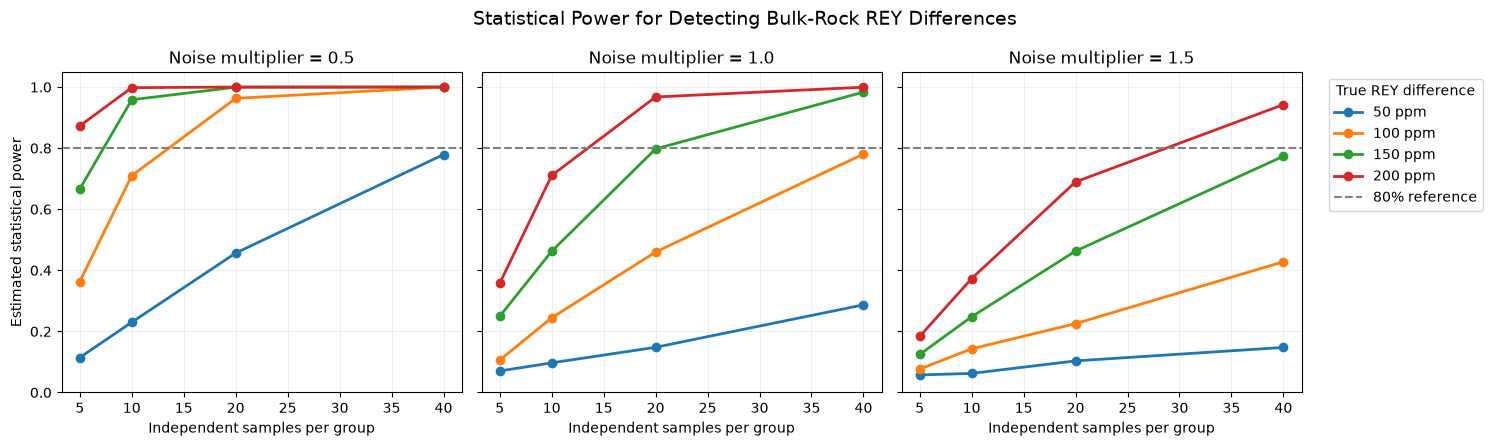

In [19]:

# Step 12C — Statistical power curves

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, noise in zip(axes, noise_levels):

    subset = power_df[
        power_df["noise_multiplier"] == noise
    ]

    for effect in [50, 100, 150, 200]:

        curve = subset[
            subset["true_effect_ppm"] == effect
        ].sort_values("n_per_group")

        ax.plot(
            curve["n_per_group"],
            curve["rejection_rate"],
            marker="o",
            linewidth=2,
            label=f"{effect} ppm"
        )

    ax.axhline(
        0.80,
        color="gray",
        linestyle="--",
        linewidth=1.5,
        label="80% reference"
    )

    ax.set_title(f"Noise multiplier = {noise}")
    ax.set_xlabel("Independent samples per group")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Estimated statistical power")

axes[-1].legend(
    title="True REY difference",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

fig.suptitle(
    "Statistical Power for Detecting Bulk-Rock REY Differences",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "figures/Study_A_Power_Curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Study A — Interpretation of Statistical Power

A Monte Carlo power analysis was performed using a two-sided Welch t-test at a nominal significance level of 0.05. The simulation examined 60 scenarios combining four sample sizes (5, 10, 20, and 40 observations per group), five true mean ΣREY differences (0, 50, 100, 150, and 200 ppm), and three noise multipliers (0.5, 1.0, and 1.5). Each scenario was simulated 2,000 times.

The simulated power curves demonstrate that statistical power generally increases with larger sample sizes and greater true mean differences, but decreases with increasing within-group variability.

For an illustrative scenario with 10 observations per group, a true difference of 100 ppm, and noise equal to the observed standard deviations, the estimated power was 25.1%.

These results emphasize the importance of both the number of independent rock specimens and their geochemical variability when designing future studies of REY enrichment.

At a true effect of zero, the simulated rejection rate estimates the Type I error rate rather than power under an alternative hypothesis.

**Limitations:** The power calculations assume independent normally distributed observations, with group standard deviations estimated from the published dataset. They are hypothetical design simulations and do not account for nonrandom field sampling, lithological heterogeneity, or spatial and stratigraphic dependence. Consequently, the results should not be interpreted as the probability that the published geological interpretation is correct.

In [20]:

# Step 12D — Save numerical power simulation results

from pathlib import Path

# Create a results folder inside the DS-A2 project
results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

# Define the output filename
output_file = results_dir / "Study_A_Power_Results.csv"

# Save all 60 simulation scenarios
power_df.to_csv(output_file, index=False)

# Independently read the saved file to verify it
saved_results = pd.read_csv(output_file)

assert len(saved_results) == 60

pd.testing.assert_frame_equal(
    saved_results,
    power_df,
    check_exact=False,
    rtol=1e-10
)

print("CSV file saved successfully!")
print("File location:", output_file.resolve())
print("Number of saved scenarios:", len(saved_results))
print("Verification passed: Saved CSV matches original results.")


CSV file saved successfully!
File location: E:\Asssessment Team\PhD\Data Science\ds_A2\DS-A2_starter\results\Study_A_Power_Results.csv
Number of saved scenarios: 60
Verification passed: Saved CSV matches original results.


## 6. Study B — In Situ Apatite REY Enrichment

**Research question:** How uncertain is the difference in mean apatite ΣREY concentrations between pseudo-oolites and pellets, accounting for repeated analytical measurements within parent rock samples and stratigraphic layers?

**Dataset:** Supplementary Table S2 of the published Kakul Garlaniyan phosphorite study.

**Sampling structure:** The number before the hyphen in each analytical point identifier represents the parent rock sample, while the number after the hyphen identifies the analytical spot.

Multiple analytical spots from the same parent rock sample may be statistically dependent. Consequently, the 103 analytical records should not automatically be treated as 103 independent geological observations.

**Initial objective:** Verify the number of analytical spots, distinct parent rock samples, and grain types represented within each stratigraphic layer before selecting a cluster-aware statistical inference method.

In [21]:

# Step 13B — Examine the Study B sampling structure

print("First 10 analytical records:")

display(
    s2[
        ["layer", "grain_type", "parent_rock_id", "sum_rey_ppm"]
    ].head(10)
)

# Count analytical spots by layer and grain type
spot_counts = (
    s2.groupby(["layer", "grain_type"])
    .size()
    .reset_index(name="n_spots")
)

# Count distinct parent rock samples
parent_counts = (
    s2.groupby(["layer", "grain_type"])
    ["parent_rock_id"]
    .nunique()
    .reset_index(name="n_parent_samples")
)

print("\nAnalytical spots by layer and grain type:")
display(spot_counts)

print("\nDistinct parent rock samples by layer and grain type:")
display(parent_counts)

print("\nTotal unique parent rock samples:")
print(s2["parent_rock_id"].nunique())


First 10 analytical records:


,layer,grain_type,parent_rock_id,sum_rey_ppm
0,LPL,pseudo-oolite,LPL:KG-2,544.948213
1,LPL,pseudo-oolite,LPL:KG-2,522.901385
2,LPL,pseudo-oolite,LPL:KG-2,662.761382
3,LPL,pseudo-oolite,LPL:KG-5,547.408153
4,LPL,pseudo-oolite,LPL:KG-5,548.375201
5,LPL,pseudo-oolite,LPL:KG-5,551.348646
6,LPL,pseudo-oolite,LPL:KG-6,729.162194
7,LPL,pseudo-oolite,LPL:KG-6,659.120304
8,LPL,pseudo-oolite,LPL:KG-4,666.975879
9,LPL,pseudo-oolite,LPL:KG-4,684.393936



Analytical spots by layer and grain type:


,layer,grain_type,n_spots
0,LPL,pellet,7
1,LPL,pseudo-oolite,14
2,MPL,pellet,16
3,MPL,pseudo-oolite,17
4,UPL,pellet,18
5,UPL,pseudo-oolite,31



Distinct parent rock samples by layer and grain type:


,layer,grain_type,n_parent_samples
0,LPL,pellet,4
1,LPL,pseudo-oolite,6
2,MPL,pellet,7
3,MPL,pseudo-oolite,9
4,UPL,pellet,5
5,UPL,pseudo-oolite,8



Total unique parent rock samples:
26


In [22]:

# Step 13C — Identify parent samples containing both grain types

# Count analytical spots by parent, layer, and grain type
parent_grain_counts = (
    s2.groupby(
        ["layer", "parent_rock_id", "grain_type"]
    )
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# Ensure both grain-type columns exist
for grain in ["pseudo-oolite", "pellet"]:
    if grain not in parent_grain_counts.columns:
        parent_grain_counts[grain] = 0

# Identify parents containing both grain types
parent_grain_counts["has_both"] = (
    (parent_grain_counts["pseudo-oolite"] > 0) &
    (parent_grain_counts["pellet"] > 0)
)

print("Analytical spots within each parent sample:")
display(parent_grain_counts)

print("\nParent samples containing both grain types:")
display(
    parent_grain_counts.groupby("layer")["has_both"]
    .agg(
        total_parents="count",
        parents_with_both="sum"
    )
)

print("\nTotal parents with both grain types:")
print(parent_grain_counts["has_both"].sum())


Analytical spots within each parent sample:


grain_type,layer,parent_rock_id,pellet,pseudo-oolite,has_both
0,LPL,LPL:KG-2,0,3,False
1,LPL,LPL:KG-4,2,2,True
2,LPL,LPL:KG-5,1,3,True
3,LPL,LPL:KG-6,2,2,True
4,LPL,LPL:KG-7,0,2,False
5,LPL,LPL:KG-8,0,2,False
6,LPL,LPL:KG-9,2,0,False
7,MPL,MPL:KG-11,0,2,False
8,MPL,MPL:KG-12,0,2,False
9,MPL,MPL:KG-13,2,2,True



Parent samples containing both grain types:


,total_parents,parents_with_both
layer,,
LPL,7,3
MPL,11,5
UPL,8,5



Total parents with both grain types:
13


In [23]:

# Step 13D — Calculate parent-level REY summaries

import pandas as pd
import numpy as np

# Calculate mean REY within each parent and grain type
parent_rey = (
    s2.groupby(
        ["layer", "parent_rock_id", "grain_type"],
        as_index=False
    )
    .agg(
        n_spots=("sum_rey_ppm", "count"),
        mean_rey_ppm=("sum_rey_ppm", "mean"),
        sd_rey_ppm=("sum_rey_ppm", "std")
    )
)

print("Parent-level REY summary:")
display(parent_rey.head(15).round(2))

print("\nNumber of parent-grain combinations:")
print(len(parent_rey))

# Each parent-grain combination should be unique
assert not parent_rey.duplicated(
    ["layer", "parent_rock_id", "grain_type"]
).any()

print("\nVerification passed: Parent-grain combinations are unique.")


Parent-level REY summary:


,layer,parent_rock_id,grain_type,n_spots,mean_rey_ppm,sd_rey_ppm
0,LPL,LPL:KG-2,pseudo-oolite,3,576.87,75.20
1,LPL,LPL:KG-4,pellet,2,509.67,6.38
2,LPL,LPL:KG-4,pseudo-oolite,2,675.68,12.32
3,LPL,LPL:KG-5,pellet,1,786.39,NaN
4,LPL,LPL:KG-5,pseudo-oolite,3,549.04,2.05
5,LPL,LPL:KG-6,pellet,2,275.73,74.89
6,LPL,LPL:KG-6,pseudo-oolite,2,694.14,49.53
7,LPL,LPL:KG-7,pseudo-oolite,2,748.83,71.41
8,LPL,LPL:KG-8,pseudo-oolite,2,734.14,5.72
9,LPL,LPL:KG-9,pellet,2,531.50,30.23



Number of parent-grain combinations:
39

Verification passed: Parent-grain combinations are unique.


In [24]:

# Step 13E — Equal-layer-weighted parent-level REY difference

# Calculate mean of parent-level REY concentrations
layer_grain_means = (
    parent_rey
    .groupby(["layer", "grain_type"])["mean_rey_ppm"]
    .mean()
    .unstack()
)

# Ensure both grain types are represented
assert layer_grain_means[
    ["pseudo-oolite", "pellet"]
].notna().all().all()

# Calculate pseudo-oolite minus pellet difference
layer_grain_means["difference_ppm"] = (
    layer_grain_means["pseudo-oolite"]
    - layer_grain_means["pellet"]
)

# Give each layer equal weight
study_b_difference = (
    layer_grain_means["difference_ppm"].mean()
)

print("Parent-weighted REY means and differences by layer:")
display(layer_grain_means.round(2))

print(
    "\nEqual-layer-weighted overall difference: "
    f"{study_b_difference:.2f} ppm"
)


Parent-weighted REY means and differences by layer:


grain_type,pellet,pseudo-oolite,difference_ppm
layer,,,
LPL,525.82,663.12,137.30
MPL,427.78,608.00,180.23
UPL,507.53,697.46,189.93



Equal-layer-weighted overall difference: 169.15 ppm


In [25]:

# Step 13F — Validate Study B bootstrap inputs

# Confirm valid parent-grain means
assert parent_rey["mean_rey_ppm"].notna().all()

# Confirm every parent belongs to one layer
parent_layers = (
    parent_rey.groupby("parent_rock_id")["layer"]
    .nunique()
)

assert (parent_layers == 1).all()

# Verify unique parent-grain combinations
assert not parent_rey.duplicated(
    ["layer", "parent_rock_id", "grain_type"]
).any()

# Check available grain types in each layer
grain_coverage = (
    parent_rey.groupby(["layer", "grain_type"])
    ["parent_rock_id"]
    .nunique()
    .unstack(fill_value=0)
)

print("Parent samples per layer and grain type:")
display(grain_coverage)

print("\nTotal unique parent samples:",
      parent_rey["parent_rock_id"].nunique())

print("\nValidation passed: Bootstrap inputs are structurally consistent.")


Parent samples per layer and grain type:


grain_type,pellet,pseudo-oolite
layer,,
LPL,4,6
MPL,7,9
UPL,5,8



Total unique parent samples: 26

Validation passed: Bootstrap inputs are structurally consistent.


In [26]:

# Step 13G — Check feasibility of whole-parent cluster resampling

import numpy as np
import pandas as pd

diagnostic_rng = np.random.default_rng(20261013)
n_diagnostic = 2000

layers = ["LPL", "MPL", "UPL"]

# One row per parent with its available grain-type means
parent_wide = (
    parent_rey.pivot(
        index=["layer", "parent_rock_id"],
        columns="grain_type",
        values="mean_rey_ppm"
    )
    .reset_index()
)

missing_group_counts = {layer: 0 for layer in layers}
valid_repetitions = 0

for _ in range(n_diagnostic):
    replicate_valid = True

    for layer in layers:
        group = parent_wide[
            parent_wide["layer"] == layer
        ]

        indices = diagnostic_rng.integers(
            0, len(group), size=len(group)
        )

        sampled = group.iloc[indices]

        if (
            sampled["pseudo-oolite"].notna().sum() == 0
            or sampled["pellet"].notna().sum() == 0
        ):
            missing_group_counts[layer] += 1
            replicate_valid = False

    if replicate_valid:
        valid_repetitions += 1

print("Diagnostic repetitions:", n_diagnostic)

print("\nReplicates missing at least one grain type, by layer:")
for layer, count in missing_group_counts.items():
    print(f"{layer}: {count}")

print("\nComplete valid replicates:", valid_repetitions)
print(
    f"Fraction complete: {valid_repetitions / n_diagnostic:.3f}"
)


Diagnostic repetitions: 2000

Replicates missing at least one grain type, by layer:
LPL: 3
MPL: 0
UPL: 1

Complete valid replicates: 1996
Fraction complete: 0.998


### Study B — Layer-Stratified Parent-Cluster Bootstrap

**Objective:** Estimate uncertainty in the equal-layer-weighted difference in mean in situ apatite ΣREY concentrations between pseudo-oolites and pellets.

The bootstrap resamples whole parent rock samples independently within LPL, MPL, and UPL, preserving the observed grain-type measurements and their associations within each parent.

Each replicate calculates parent-weighted grain-type means within each layer, followed by the pseudo-oolite minus pellet difference. The overall statistic is the equally weighted average of the three layer-specific differences.

The procedure uses 10,000 bootstrap attempts with a fixed random seed.

Replicates lacking either grain type in any layer are recorded as incomplete and excluded from the percentile calculation. The resulting interval is therefore conditional on complete group representation, and the exclusion frequency is reported.

**Limitations:** The method assumes that parent rock samples are suitable independent resampling units within layers. It does not account for possible dependence between different parent rocks, nonrandom sample selection, or uncertainty in grain-type classification. Percentile bootstrap intervals may have imperfect coverage with small numbers of parent samples.

In [27]:

# Step 13H — Layer-stratified parent-cluster bootstrap

import numpy as np

cluster_rng = np.random.default_rng(20261013)
n_cluster_bootstrap = 10000

layers = ["LPL", "MPL", "UPL"]

# Precompute parent-level data for each layer
layer_parent_data = {
    layer: parent_wide[parent_wide["layer"] == layer]
    .reset_index(drop=True)
    for layer in layers
}

cluster_bootstrap_differences = []
incomplete_replicates = 0

for _ in range(n_cluster_bootstrap):

    layer_differences = []
    complete = True

    for layer in layers:

        group = layer_parent_data[layer]

        # Resample whole parent rocks with replacement
        indices = cluster_rng.integers(
            0, len(group), size=len(group)
        )

        sampled = group.iloc[indices]

        pseudo_mean = sampled["pseudo-oolite"].mean()
        pellet_mean = sampled["pellet"].mean()

        if not (
            np.isfinite(pseudo_mean)
            and np.isfinite(pellet_mean)
        ):
            complete = False
            break

        layer_differences.append(
            pseudo_mean - pellet_mean
        )

    if complete:
        cluster_bootstrap_differences.append(
            np.mean(layer_differences)
        )
    else:
        incomplete_replicates += 1

cluster_bootstrap_differences = np.asarray(
    cluster_bootstrap_differences
)

assert (
    len(cluster_bootstrap_differences)
    + incomplete_replicates
    == n_cluster_bootstrap
)

cluster_ci = np.percentile(
    cluster_bootstrap_differences,
    [2.5, 97.5]
)

print(f"Observed Study B difference: {study_b_difference:.2f} ppm")
print(f"Bootstrap attempts: {n_cluster_bootstrap}")
print(f"Complete replicates: {len(cluster_bootstrap_differences)}")
print(f"Incomplete replicates: {incomplete_replicates}")

print(
    f"Bootstrap standard error: "
    f"{cluster_bootstrap_differences.std(ddof=1):.2f} ppm"
)

print(
    f"95% cluster bootstrap CI: "
    f"[{cluster_ci[0]:.2f}, {cluster_ci[1]:.2f}] ppm"
)


Observed Study B difference: 169.15 ppm
Bootstrap attempts: 10000
Complete replicates: 9977
Incomplete replicates: 23
Bootstrap standard error: 40.55 ppm
95% cluster bootstrap CI: [87.55, 247.97] ppm


### Study B — Cluster Bootstrap Results and Interpretation

The in situ apatite dataset comprises 103 analytical spots from 26 parent rock samples. To reduce pseudoreplication, analytical measurements were first summarized within parent rocks and grain types, followed by equally weighted stratigraphic-layer comparisons.

The estimated overall difference in mean ΣREY concentrations between pseudo-oolites and pellets was **169.15 ppm**, with higher concentrations in pseudo-oolites.

A layer-stratified parent-cluster bootstrap was performed using 10,000 resampling attempts. Of these, 9,977 produced complete grain-type comparisons across all three layers, while 23 were incomplete and excluded from the percentile calculation.

The estimated bootstrap standard error was **40.55 ppm**, and the conditional 95% percentile bootstrap confidence interval was **87.55–247.97 ppm**.

The interval excludes zero, supporting a positive grain-type-associated difference under the specified resampling assumptions. However, it overlaps the provisional 100 ppm meaningful-effect benchmark, so a difference exceeding that threshold is not established at this confidence level.

**Limitations:** Parent-rock resampling addresses clustering of analytical spots within rock samples but does not establish independence between different parent rocks, random geological sampling, or causality. The exclusion of incomplete bootstrap repetitions and the small numbers of parent samples may affect interval coverage. The analysis also gives equal weight to stratigraphic layers, which is a deliberate statistical choice rather than a representation of their geological abundance.

The results should therefore be interpreted as conditional evidence of grain-type-associated REY enrichment, not definitive proof of a particular phosphogenesis mechanism.

## 7. Assumption-Violating Counterexample — Pseudoreplication

**Objective:** Demonstrate how incorrectly treating repeated analytical spots as independent observations can affect statistical uncertainty and hypothesis-testing conclusions.

The counterexample will use synthetic data with a known true mean difference of zero between pseudo-oolites and pellets. Observations will be grouped within simulated parent rock samples, with positive within-parent correlation introduced through shared parent-level effects.

Two analysis strategies will be compared:

1. A naive analysis that treats every analytical spot as independent.
2. A cluster-aware analysis that respects parent-rock grouping.

Both approaches will target the same underlying grain-type difference so that changes in statistical conclusions can be attributed to the treatment of dependence rather than changes in the estimand.

The simulation will evaluate false-positive rates and confidence-interval coverage across repeated datasets.

**Scientific relevance:** Multiple in situ measurements from a single phosphorite sample may share geological and diagenetic characteristics. Failing to account for these relationships can lead to pseudoreplication.

**Limitations:** The synthetic data are hypothetical and do not represent additional geological observations. The specified correlation structure is a demonstration of an assumption violation, not an empirical estimate of correlation in the original dataset.

In [28]:

# Step 14B — Generate synthetic clustered geochemical data

import numpy as np
import pandas as pd

counter_rng = np.random.default_rng(20261013)

n_parents = 20
spots_per_grain_type = 4

true_grain_difference = 0.0

parent_sd = 100.0
spot_sd = 50.0
baseline_rey = 500.0

synthetic_records = []

for parent in range(n_parents):

    # Shared geochemical effect for this parent rock
    parent_effect = counter_rng.normal(
        loc=0, scale=parent_sd
    )

    for grain_type in ["pseudo-oolite", "pellet"]:

        grain_effect = (
            true_grain_difference
            if grain_type == "pseudo-oolite"
            else 0.0
        )

        for spot in range(spots_per_grain_type):

            spot_effect = counter_rng.normal(
                loc=0, scale=spot_sd
            )

            rey_value = (
                baseline_rey
                + parent_effect
                + grain_effect
                + spot_effect
            )

            synthetic_records.append({
                "parent_id": parent,
                "grain_type": grain_type,
                "spot_id": spot + 1,
                "rey_ppm": rey_value
            })

synthetic_df = pd.DataFrame(synthetic_records)

print("Total synthetic analytical spots:", len(synthetic_df))
print("Number of synthetic parent rocks:",
      synthetic_df["parent_id"].nunique())

print("\nFirst 10 synthetic records:")
display(synthetic_df.head(10))


Total synthetic analytical spots: 160
Number of synthetic parent rocks: 20

First 10 synthetic records:


,parent_id,grain_type,spot_id,rey_ppm
0,0,pseudo-oolite,1,594.557320
1,0,pseudo-oolite,2,539.953032
2,0,pseudo-oolite,3,597.533741
3,0,pseudo-oolite,4,548.723791
4,0,pellet,1,563.902109
5,0,pellet,2,570.686661
6,0,pellet,3,500.601195
7,0,pellet,4,612.897965
8,1,pseudo-oolite,1,550.527819
9,1,pseudo-oolite,2,550.873974


In [29]:

# Step 14C — Compare naive and parent-aware inference

from scipy import stats
import numpy as np

# Naive approach: treat all analytical spots as independent
naive_pseudo = synthetic_df.loc[
    synthetic_df["grain_type"] == "pseudo-oolite", "rey_ppm"
].to_numpy()

naive_pellet = synthetic_df.loc[
    synthetic_df["grain_type"] == "pellet", "rey_ppm"
].to_numpy()

naive_test = stats.ttest_ind(
    naive_pseudo,
    naive_pellet,
    equal_var=False
)

naive_ci = naive_test.confidence_interval(
    confidence_level=0.95
)

# Parent-aware approach: calculate mean for each grain type in each parent
parent_means = (
    synthetic_df
    .groupby(["parent_id", "grain_type"])["rey_ppm"]
    .mean()
    .unstack()
)

parent_differences = (
    parent_means["pseudo-oolite"] - parent_means["pellet"]
)

paired_result = stats.ttest_1samp(
    parent_differences,
    popmean=0
)

paired_ci = paired_result.confidence_interval(
    confidence_level=0.95
)

print("NAIVE ANALYSIS (160 analytical spots)")
print(f"Estimated difference: {naive_pseudo.mean() - naive_pellet.mean():.2f} ppm")
print(f"95% CI: [{naive_ci.low:.2f}, {naive_ci.high:.2f}] ppm")
print(f"p-value: {naive_test.pvalue:.4f}")

print("\nPARENT-AWARE ANALYSIS (20 parent rocks)")
print(f"Estimated difference: {parent_differences.mean():.2f} ppm")
print(f"95% CI: [{paired_ci.low:.2f}, {paired_ci.high:.2f}] ppm")
print(f"p-value: {paired_result.pvalue:.4f}")


NAIVE ANALYSIS (160 analytical spots)
Estimated difference: -0.30 ppm
95% CI: [-39.30, 38.71] ppm
p-value: 0.9880

PARENT-AWARE ANALYSIS (20 parent rocks)
Estimated difference: -0.30 ppm
95% CI: [-15.60, 15.01] ppm
p-value: 0.9681


In [30]:

# Step 14D — Repeated-experiment comparison

import numpy as np
import pandas as pd
from scipy import stats

repeat_rng = np.random.default_rng(20261014)

n_experiments = 2000
n_parents = 20
spots_per_type = 4

parent_sd = 100.0
spot_sd = 50.0
true_difference = 0.0
baseline = 500.0
alpha = 0.05

results = []

for experiment in range(n_experiments):

    # Shared parent-rock effects
    parent_effects = repeat_rng.normal(
        0, parent_sd, size=n_parents
    )

    # Separate spot-level noise for both grain types
    pseudo = (
        baseline
        + parent_effects[:, None]
        + true_difference
        + repeat_rng.normal(
            0, spot_sd, size=(n_parents, spots_per_type)
        )
    )

    pellet = (
        baseline
        + parent_effects[:, None]
        + repeat_rng.normal(
            0, spot_sd, size=(n_parents, spots_per_type)
        )
    )

    # Naive unpaired Welch test
    naive = stats.ttest_ind(
        pseudo.ravel(),
        pellet.ravel(),
        equal_var=False
    )

    naive_ci = naive.confidence_interval(0.95)

    # Parent-aware paired test
    paired_differences = (
        pseudo.mean(axis=1) - pellet.mean(axis=1)
    )

    aware = stats.ttest_1samp(
        paired_differences, popmean=0
    )

    aware_ci = aware.confidence_interval(0.95)

    results.append({
        "naive_reject": naive.pvalue < alpha,
        "aware_reject": aware.pvalue < alpha,
        "naive_cover": naive_ci.low <= 0 <= naive_ci.high,
        "aware_cover": aware_ci.low <= 0 <= aware_ci.high
    })

counter_results = pd.DataFrame(results)

print("Repeated synthetic experiments:", n_experiments)

print("\nFalse-positive rate:")
print("Naive:", round(counter_results["naive_reject"].mean(), 4))
print("Parent-aware:", round(counter_results["aware_reject"].mean(), 4))

print("\n95% confidence interval coverage:")
print("Naive:", round(counter_results["naive_cover"].mean(), 4))
print("Parent-aware:", round(counter_results["aware_cover"].mean(), 4))

print("\nFraction of experiments with conflicting decisions:")
print(
    round(
        (counter_results["naive_reject"]
         != counter_results["aware_reject"]).mean(),
        4
    )
)


Repeated synthetic experiments: 2000

False-positive rate:
Naive: 0.0005
Parent-aware: 0.0535

95% confidence interval coverage:
Naive: 0.9995
Parent-aware: 0.9465

Fraction of experiments with conflicting decisions:
0.053


### Study B — Interpretation of the Assumption-Violating Counterexample

A controlled Monte Carlo counterexample was constructed to examine the consequences of treating repeated geochemical analytical spots as independent observations.

The simulation generated 2,000 synthetic experiments, each containing 20 parent rock samples with four analytical spots per grain type. The true difference in mean ΣREY concentration between pseudo-oolites and pellets was set to zero. Shared parent-rock effects introduced positive dependence among measurements from the same rock.

Two inference methods were compared: an unpaired Welch test treating 160 analytical spots as independent and a parent-aware paired t-test using within-parent grain-type differences.

The naive method produced a false-positive rate of **0.05%** and 95% confidence-interval coverage of **99.95%**. The parent-aware method produced a false-positive rate of **5.35%** and coverage of **94.65%**, closer to the nominal 5% significance and 95% confidence levels.

The methods disagreed on statistical significance in **5.3%** of the simulated experiments.

In this balanced paired design, ignoring the parent-rock structure produced excessively conservative inference rather than inflated false-positive rates. Because both grain types shared parent-level variation, within-parent differences cancelled much of that variation, improving the precision of the parent-aware analysis.

**Scientific implication:** Repeated analytical spots cannot automatically be treated as independent geological sampling units. The effect of ignoring dependence depends on the sampling design, the estimand, and the correlation structure.

**Limitations:** The experiment is synthetic and assumes a balanced paired design that differs from the partially paired structure of the original in situ dataset. Its results should not be interpreted as empirically estimated false-positive rates for the published geological observations.

In [31]:

# Step 15A — Save and verify counterexample results

from pathlib import Path
import pandas as pd

results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

counter_file = results_dir / "Study_B_Counterexample_Results.csv"

# Preserve all 2,000 experimental outcomes
counter_results.to_csv(counter_file, index=False)

# Independently reload and verify
reloaded = pd.read_csv(counter_file)

assert len(reloaded) == 2000

pd.testing.assert_frame_equal(
    reloaded,
    counter_results
)

print("Counterexample CSV saved successfully!")
print("File:", counter_file.resolve())
print("Experiments saved:", len(reloaded))
print("Verification passed: CSV matches original results.")


Counterexample CSV saved successfully!
File: E:\Asssessment Team\PhD\Data Science\ds_A2\DS-A2_starter\results\Study_B_Counterexample_Results.csv
Experiments saved: 2000
Verification passed: CSV matches original results.


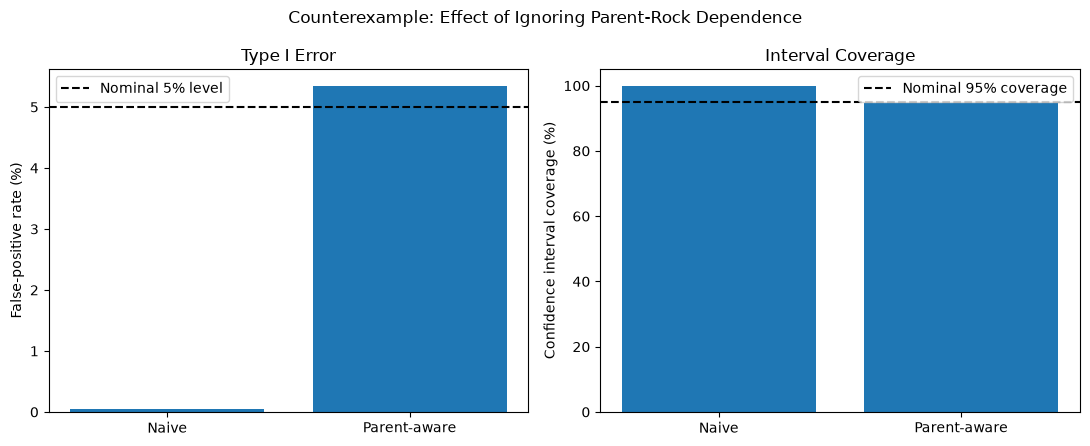

In [32]:

# Step 15B — Visualize counterexample results

import matplotlib.pyplot as plt
import numpy as np

methods = ["Naive", "Parent-aware"]

false_positive_rates = [
    counter_results["naive_reject"].mean() * 100,
    counter_results["aware_reject"].mean() * 100
]

coverage_rates = [
    counter_results["naive_cover"].mean() * 100,
    counter_results["aware_cover"].mean() * 100
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# False-positive rates
axes[0].bar(methods, false_positive_rates)
axes[0].axhline(
    5, color="black", linestyle="--",
    label="Nominal 5% level"
)
axes[0].set_ylabel("False-positive rate (%)")
axes[0].set_title("Type I Error")
axes[0].legend()

# Confidence interval coverage
axes[1].bar(methods, coverage_rates)
axes[1].axhline(
    95, color="black", linestyle="--",
    label="Nominal 95% coverage"
)
axes[1].set_ylabel("Confidence interval coverage (%)")
axes[1].set_title("Interval Coverage")
axes[1].set_ylim(0, 105)
axes[1].legend()

fig.suptitle(
    "Counterexample: Effect of Ignoring Parent-Rock Dependence"
)

plt.tight_layout()

plt.savefig(
    "figures/Study_B_Counterexample_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [33]:

# Step 17B — Record computational environment

import sys
import platform
import numpy
import pandas
import scipy
import matplotlib
import openpyxl

print("Operating system:", platform.platform())
print("Python version:", sys.version)
print("Python executable:", sys.executable)

print("\nScientific package versions:")
print("NumPy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("openpyxl:", openpyxl.__version__)

print("\nDependency lock file: requirements-lock.txt")


Operating system: Windows-11-10.0.26300-SP0
Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Python executable: e:\Asssessment Team\PhD\Data Science\.venv\Scripts\python.exe

Scientific package versions:
NumPy: 2.5.4
pandas: 3.0.6
SciPy: 1.18.1
Matplotlib: 3.11.2
openpyxl: 3.1.5

Dependency lock file: requirements-lock.txt


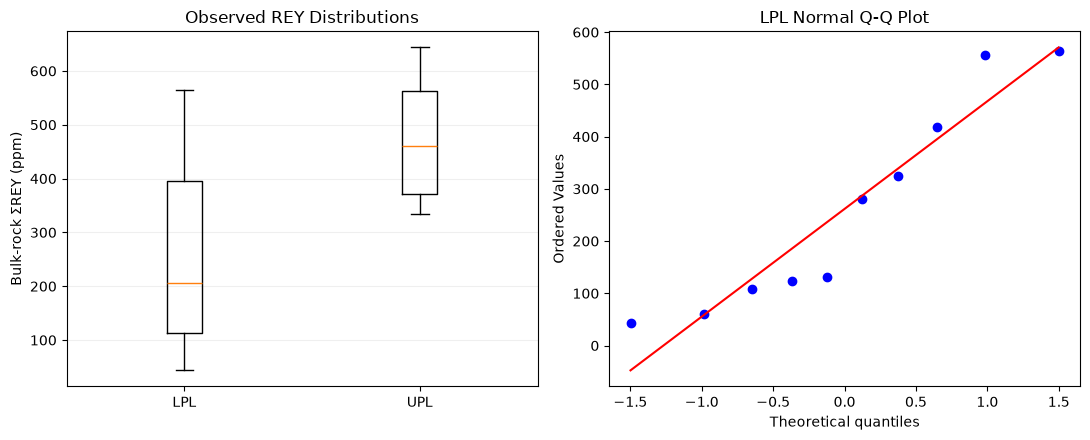

Study A distribution diagnostics:


,layer,n,mean_ppm,median_ppm,sd_ppm,skewness
0,LPL,10,261.6,206.43,198.58,0.55
1,UPL,8,471.9,460.56,121.03,0.19


In [34]:

# Step 19C — Study A distribution and assumption diagnostics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Display actual observations
axes[0].boxplot(
    [lpl, upl],
    tick_labels=["LPL", "UPL"]
)

axes[0].set_ylabel("Bulk-rock ΣREY (ppm)")
axes[0].set_title("Observed REY Distributions")
axes[0].grid(axis="y", alpha=0.2)

# Normal Q-Q plots
stats.probplot(lpl, dist="norm", plot=axes[1])
axes[1].set_title("LPL Normal Q-Q Plot")

plt.tight_layout()
plt.show()

# Descriptive diagnostics
diagnostics = pd.DataFrame({
    "layer": ["LPL", "UPL"],
    "n": [len(lpl), len(upl)],
    "mean_ppm": [np.mean(lpl), np.mean(upl)],
    "median_ppm": [np.median(lpl), np.median(upl)],
    "sd_ppm": [
        np.std(lpl, ddof=1),
        np.std(upl, ddof=1)
    ],
    "skewness": [
        stats.skew(lpl, bias=False),
        stats.skew(upl, bias=False)
    ]
})

print("Study A distribution diagnostics:")
display(diagnostics.round(2))


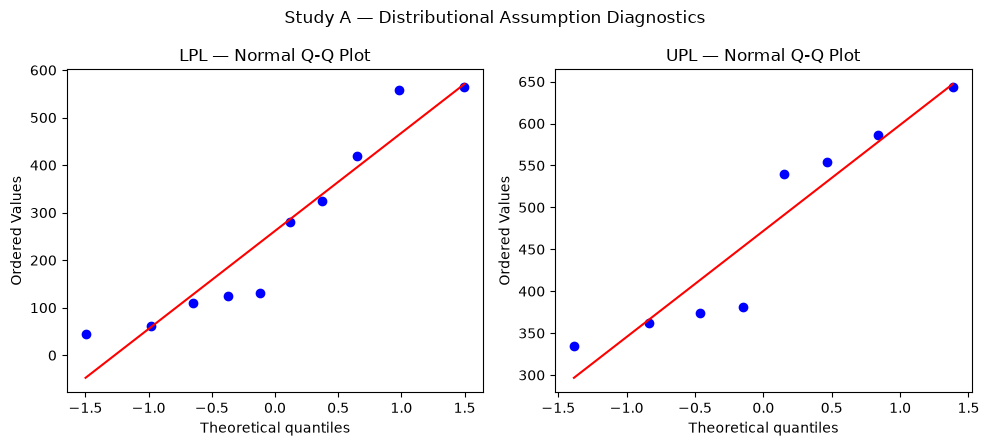

In [35]:

# Step 19D — Compare normal Q-Q plots for both layers

from scipy import stats
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

stats.probplot(lpl, dist="norm", plot=axes[0])
axes[0].set_title("LPL — Normal Q-Q Plot")

stats.probplot(upl, dist="norm", plot=axes[1])
axes[1].set_title("UPL — Normal Q-Q Plot")

fig.suptitle("Study A — Distributional Assumption Diagnostics")

plt.tight_layout()
plt.show()


### Study A — Assessment of Distributional Assumptions

Distributional diagnostics were examined for the bulk-rock ΣREY observations in the Lower and Upper phosphorite layers.

The LPL group contained 10 observations, with a mean of 261.60 ppm, median of 206.43 ppm, standard deviation of 198.58 ppm, and sample skewness of 0.55. The UPL group contained eight observations, with a mean of 471.90 ppm, median of 460.56 ppm, standard deviation of 121.03 ppm, and sample skewness of 0.19.

The normal Q-Q plots showed departures from the theoretical reference lines in both groups, particularly in the LPL data. However, the small numbers of observations prevent strong conclusions regarding distributional normality.

The larger variability in LPL supports the choice of an unequal-variance Welch procedure rather than an equal-variance pooled t-method. Nevertheless, Welch's method does not automatically correct for non-normality, geological dependence, or nonrandom sampling.

The percentile bootstrap provides a complementary uncertainty estimate without requiring an explicitly normal population model, but its reliability is also limited by the small sample sizes and representativeness of the observations.

The previously observed reduction of the UPL–LPL difference from 210.30 ppm to 16.54 ppm after restricting the comparison to phosphorite samples further indicates that lithological composition is an important source of interpretive sensitivity.

Accordingly, the original whole-rock enrichment result is retained as a descriptive and conditional inferential finding, rather than definitive evidence that stratigraphic position independently controls REY enrichment.

In [36]:

# Step 19F — Paired-parent sensitivity analysis

import pandas as pd
import numpy as np

# Start with parent-level mean concentrations
paired_parent_data = parent_wide.dropna(
    subset=["pseudo-oolite", "pellet"]
).copy()

# Calculate within-parent grain-type differences
paired_parent_data["paired_difference_ppm"] = (
    paired_parent_data["pseudo-oolite"]
    - paired_parent_data["pellet"]
)

print("Paired parent-rock comparisons:")
display(
    paired_parent_data[
        [
            "layer",
            "parent_rock_id",
            "pseudo-oolite",
            "pellet",
            "paired_difference_ppm"
        ]
    ].round(2)
)

# Summarize by layer
paired_summary = (
    paired_parent_data
    .groupby("layer")["paired_difference_ppm"]
    .agg(
        n_parents="count",
        mean_difference_ppm="mean",
        sd_difference_ppm="std",
        median_difference_ppm="median"
    )
)

print("\nWithin-parent differences by layer:")
display(paired_summary.round(2))

# Equal-layer-weighted paired estimate
paired_overall_difference = (
    paired_summary["mean_difference_ppm"].mean()
)

print(
    "\nEqual-layer-weighted paired-parent difference: "
    f"{paired_overall_difference:.2f} ppm"
)

print(
    "Original Study B difference: "
    f"{study_b_difference:.2f} ppm"
)


Paired parent-rock comparisons:


grain_type,layer,parent_rock_id,pseudo-oolite,pellet,paired_difference_ppm
1,LPL,LPL:KG-4,675.68,509.67,166.01
2,LPL,LPL:KG-5,549.04,786.39,-237.35
3,LPL,LPL:KG-6,694.14,275.73,418.41
9,MPL,MPL:KG-13,637.34,472.18,165.16
10,MPL,MPL:KG-14,542.30,348.29,194.01
11,MPL,MPL:KG-15,612.03,328.50,283.53
13,MPL,MPL:KG-17,640.40,450.37,190.04
16,MPL,MPL:KG-20,539.74,362.90,176.84
19,UPL,UPL:KG-23,741.84,494.50,247.34
20,UPL,UPL:KG-24,636.85,550.44,86.41



Within-parent differences by layer:


,n_parents,mean_difference_ppm,sd_difference_ppm,median_difference_ppm
layer,,,,
LPL,3,115.69,330.76,166.01
MPL,5,201.92,47.02,190.04
UPL,5,195.04,62.61,215.25



Equal-layer-weighted paired-parent difference: 170.88 ppm
Original Study B difference: 169.15 ppm


### Study B — Paired-Parent Sensitivity Interpretation

A paired-parent sensitivity analysis was conducted using the 13 parent rock samples that contained both pseudo-oolite and pellet apatite measurements.

Within each parent, mean ΣREY concentrations were calculated separately for the two grain types. Their difference was then determined, and the resulting differences were summarized within each stratigraphic layer.

The mean within-parent differences were 115.69 ppm for LPL (3 parents), 201.92 ppm for MPL (5 parents), and 195.04 ppm for UPL (5 parents).

The equal-layer-weighted paired-parent difference was **170.88 ppm**, compared with **169.15 ppm** in the original parent-weighted analysis. The difference between these estimates was 1.73 ppm.

This close agreement indicates that the positive grain-type contrast is descriptively consistent when analysis is restricted to the parent samples containing both grain types.

However, the LPL paired differences showed substantial variation (SD = 330.76 ppm), with only three paired parent samples. Consequently, the paired-parent estimate remains uncertain and may be sensitive to individual observations.

The restricted analysis also changes the sampled population and cannot establish that the original result is unaffected by sample-selection bias.

These findings provide a supporting sensitivity assessment rather than independent confirmation of the primary Study B confidence interval or a causal explanation for REY enrichment.